# Temporal validation of the Collins flood damage probability map

The published Collins map was evaluated against NOAA Flood and Flash Flood reports from **June 2020 through December 2025**, following the original model's training period. The analysis measures discrimination between reported flood locations and sampled background locations at the map's native 100 m resolution.

The primary analysis included **32,091 unique reported cells**. ROC AUC was **0.696** (approximate 95% spatial-bootstrap interval: **0.689–0.703**). The highest-scoring **20% of eligible area within each watershed region contained 45.0% of reported cells**, compared with an expected 20% under random selection. Performance varied by watershed region and event type.

These results evaluate the published map without refitting. They do not establish calibrated flood probabilities or the effect of retraining on more recent reports. This notebook presents archived results from the completed local validation run.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE = Path.cwd()
if not (BASE / 'metrics.json').exists():
    BASE = BASE / 'input-data/tensor/fdp/validation-2026-10-15'
assert (BASE / 'metrics.json').exists(), (
    "Run from the repository root or this notebook's directory."
)
ROOT = BASE.parents[3]
metrics = json.loads((BASE / 'metrics.json').read_text())
manifest = json.loads((BASE / 'manifest.json').read_text())
groups = pd.read_csv(BASE / 'metrics_by_group.csv', dtype={'group': str})
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 80)

plt.rcParams.update(
    {
        'font.size': 11,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.titleweight': 'bold',
        'axes.titlepad': 16,
        'figure.dpi': 110,
        'savefig.dpi': 160,
    }
)
TEAL, GRAY, ORANGE = '#087f75', '#b3bdc7', '#b66124'


def finish(fig, filename):
    fig.savefig(BASE / filename, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

## 1. Capture of reported locations by area threshold

Map-score thresholds were used to select the highest-scoring 10% and 20% of eligible area within each of the 18 major watershed regions in the contiguous United States. **HUC-2** denotes the two-digit Hydrologic Unit Code identifying each region; these regions group drainage areas. Full region names are used in the regional figure below.

Capture is the fraction of unique reported 100 m cells included above each threshold. Repeated reports in the same cell are counted once. Random selection of the same area fraction provides the reference expectation.

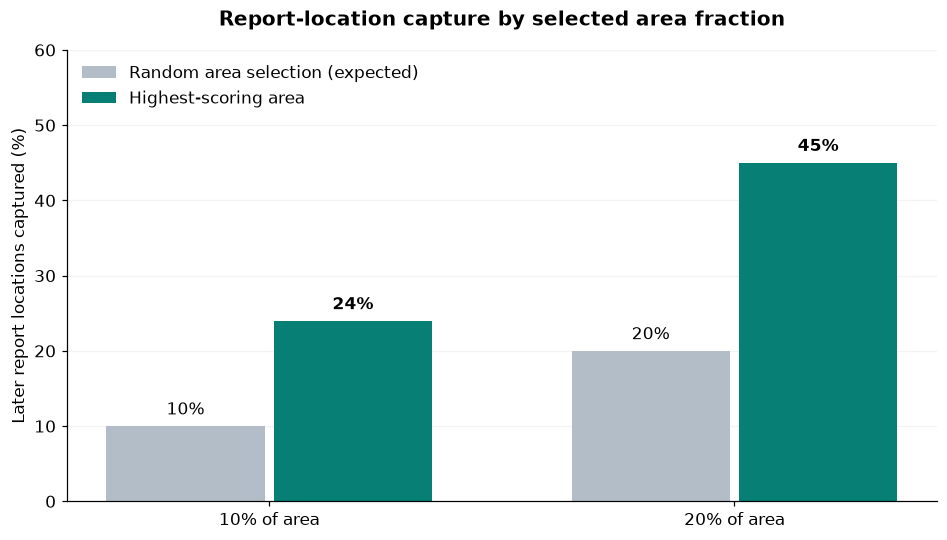

In [2]:
m = metrics['all_reports_unique_cells']
selected = np.array([10, 20])
captured = 100 * np.array([m['recall_top10_huc_area'], m['recall_top20_huc_area']])
x = np.arange(2)
fig, ax = plt.subplots(figsize=(8.5, 4.8), layout='constrained')
a = ax.bar(x - 0.18, selected, width=0.34, color=GRAY, label='Random area selection (expected)')
b = ax.bar(x + 0.18, captured, width=0.34, color=TEAL, label='Highest-scoring area')
ax.bar_label(a, labels=[f'{v:.0f}%' for v in selected], padding=5)
ax.bar_label(b, labels=[f'{v:.0f}%' for v in captured], padding=5, fontweight='bold')
ax.set(
    xticks=x,
    xticklabels=['10% of area', '20% of area'],
    ylim=(0, 60),
    ylabel='Later report locations captured (%)',
    title='Report-location capture by selected area fraction',
)
ax.legend(frameon=False, loc='upper left')
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.15)
finish(fig, 'area_capture.png')

The highest-scoring 20% of eligible area captured **45.0%** of reported cells, or **2.25 times** the expected capture under random selection. The remaining **55.0%** fell outside the selected area; low scores therefore do not establish the absence of flood exposure.

For the subset with recorded monetary damage, injury or death, capture was **42.6% in the highest-scoring 20% of area**. Reports without recorded impacts may contain missing impact fields or narrative-only descriptions and are not necessarily damage-free.

Ties at each score threshold were allocated fractionally, equivalent to expected capture under random tie-breaking. This preserves the specified area fraction when multiple cells share the cutoff score.

## 2. Overall discrimination

**ROC AUC** is the probability that a randomly selected reported location receives a higher map score than a randomly selected background location, with half-credit for tied scores. An AUC of 0.5 indicates chance-level discrimination; 1.0 indicates complete separation. Figures express AUC as a percentage for readability.

Overall AUC was **0.696** for all reported cells and **0.683** for cells with recorded impacts. These values measure ranking performance, not classification accuracy or annual flood probability.

Background locations were weighted to match each report cohort's watershed-region distribution. They had no known report in the records used for exclusion, but were not confirmed non-flooded sites.

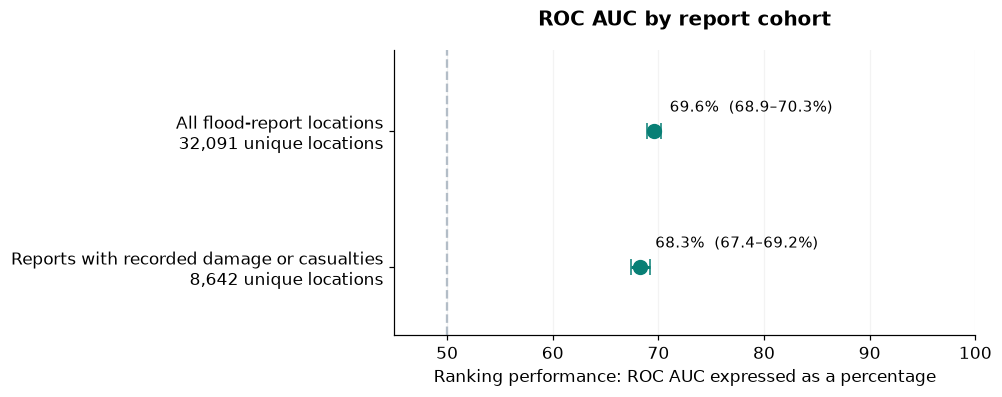

In [3]:
keys = ['all_reports_unique_cells', 'recorded_impact_unique_cells']
labels = [
    'All flood-report locations\n32,091 unique locations',
    'Reports with recorded damage or casualties\n8,642 unique locations',
]
values = np.array([metrics[k]['auc'] for k in keys]) * 100
intervals = np.array([metrics[k]['auc_95ci_50km_block_poisson'] for k in keys]) * 100
fig, ax = plt.subplots(figsize=(9, 3.5), layout='constrained')
y = np.array([1, 0])
ax.errorbar(
    values,
    y,
    xerr=np.vstack([values - intervals[:, 0], intervals[:, 1] - values]),
    fmt='o',
    color=TEAL,
    markersize=9,
    capsize=5,
    linewidth=2,
)
for yy, v, ci in zip(y, values, intervals):
    ax.annotate(
        f'{v:.1f}%  ({ci[0]:.1f}–{ci[1]:.1f}%)',
        (v, yy),
        xytext=(10, 13),
        textcoords='offset points',
        fontsize=10,
    )
ax.axvline(50, color=GRAY, linestyle='--')
ax.set(
    yticks=y,
    yticklabels=labels,
    xlim=(45, 100),
    ylim=(-0.5, 1.6),
    xlabel='Ranking performance: ROC AUC expressed as a percentage',
    title='ROC AUC by report cohort',
)
ax.set_xticks([50, 60, 70, 80, 90, 100])
ax.grid(axis='x', alpha=0.15)
finish(fig, 'ranking_performance.png')

Error bars indicate approximate 95% intervals from resampling 50 km spatial blocks. These intervals represent sampling variability under the evaluation design; they do not account for reporting bias or alternative background-selection methods.

The estimates are **not directly comparable with the paper's AUC of 0.750**. The paper controlled comparison locations using land cover and floodplain boundaries; this evaluation controls only the watershed-region distribution. Differences in development and exposure may contribute to the measured discrimination.

## 3. Regional and event-type results

Within each watershed region, reported cells were compared with background cells from that region. Regional AUC was lowest in **Lower Mississippi (0.554)** and **South Atlantic-Gulf (0.612)**. Sample counts are shown alongside the estimates.

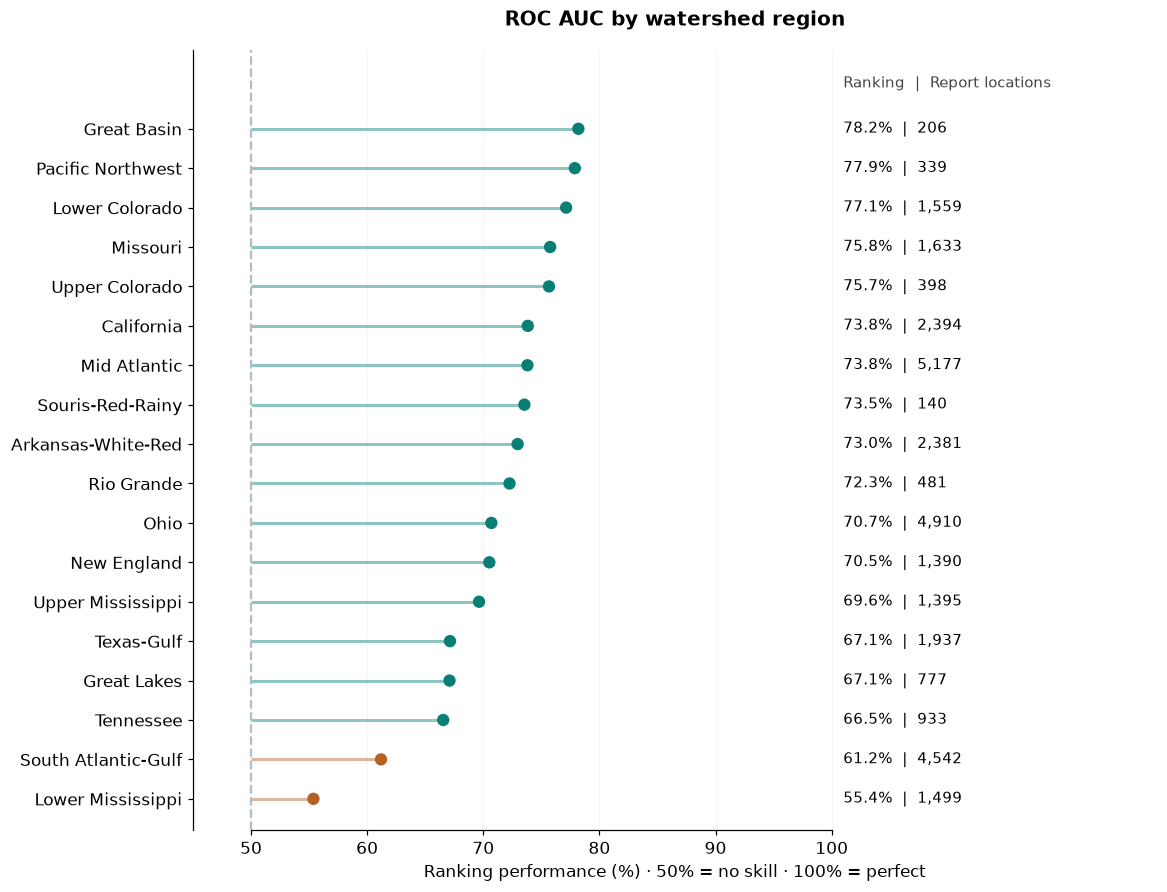

In [4]:
names = {
    '01': 'New England',
    '02': 'Mid Atlantic',
    '03': 'South Atlantic-Gulf',
    '04': 'Great Lakes',
    '05': 'Ohio',
    '06': 'Tennessee',
    '07': 'Upper Mississippi',
    '08': 'Lower Mississippi',
    '09': 'Souris-Red-Rainy',
    '10': 'Missouri',
    '11': 'Arkansas-White-Red',
    '12': 'Texas-Gulf',
    '13': 'Rio Grande',
    '14': 'Upper Colorado',
    '15': 'Lower Colorado',
    '16': 'Great Basin',
    '17': 'Pacific Northwest',
    '18': 'California',
}
regions = groups[groups.grouping == 'huc2'].sort_values('auc').copy()
regions['region_name'] = regions.group.map(names)
y = np.arange(len(regions))
fig, ax = plt.subplots(figsize=(10.5, 8), layout='constrained')
colors = [ORANGE if h in ['03', '08'] else TEAL for h in regions.group]
ax.hlines(y, 50, regions.auc * 100, color=colors, linewidth=2, alpha=0.45)
ax.scatter(regions.auc * 100, y, c=colors, s=50, zorder=3)
for yy, row in zip(y, regions.itertuples()):
    ax.text(101, yy, f'{100 * row.auc:.1f}%  |  {row.n_positive:,}', va='center', fontsize=10)
ax.text(101, len(regions) + 0.05, 'Ranking  |  Report locations', fontsize=10, color='#444444')
ax.axvline(50, color=GRAY, linestyle='--', linewidth=1.5)
ax.set(
    yticks=y,
    yticklabels=regions.region_name,
    xlim=(45, 128),
    ylim=(-0.8, len(regions) + 1),
    xticks=[50, 60, 70, 80, 90, 100],
    xlabel='Ranking performance (%) · 50% = no skill · 100% = perfect',
    title='ROC AUC by watershed region',
)
ax.spines['bottom'].set_bounds(50, 100)
ax.grid(axis='x', alpha=0.12)
finish(fig, 'watershed_regions.png')

Regional results use all flood reports rather than only the recorded-impact subset. Regional uncertainty intervals were not calculated, so differences between regions have not been assessed for statistical significance.

AUC was **0.740 for Flood reports** and **0.677 for Flash Flood reports** under this evaluation design.

## 4. Annual results

Annual AUC ranged from approximately **0.687 to 0.712**, with no monotonic decline over the evaluation period. No formal trend test was performed.

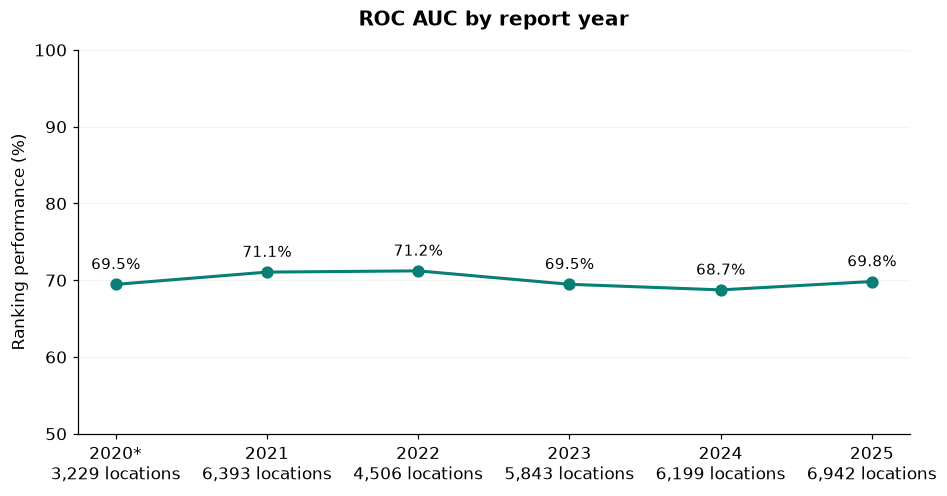

In [5]:
years = groups[groups.grouping == 'year'].copy()
fig, ax = plt.subplots(figsize=(8.5, 4.4), layout='constrained')
x = np.arange(len(years))
ax.plot(x, years.auc * 100, 'o-', color=TEAL, linewidth=2, markersize=7)
for xx, row in zip(x, years.itertuples()):
    ax.annotate(
        f'{100 * row.auc:.1f}%',
        (xx, 100 * row.auc),
        xytext=(0, 10),
        textcoords='offset points',
        ha='center',
        fontsize=10,
    )
ax.set(
    xticks=x,
    xticklabels=[
        f'{r.group}{"*" if r.group == "2020" else ""}\n{r.n_positive:,} locations'
        for r in years.itertuples()
    ],
    ylim=(50, 100),
    ylabel='Ranking performance (%)',
    title='ROC AUC by report year',
)
ax.grid(axis='y', alpha=0.15)
finish(fig, 'performance_by_year.png')

*2020 covers June–December only; other years cover January–December. Locations are counted once within each year, so annual counts do not sum to the all-years unique count.*

## 5. Implications for model retraining

This evaluation does not estimate the benefit of retraining with updated damage reports. It tests only the published, fixed map.

AUC was **0.688** for newly reported cells and **0.829** for cells also represented in the older records. Historical overlap was reconstructed from current NOAA records rather than the original training archive. This difference may reflect training-period representation, predictor limitations, reporting patterns or location uncertainty; it does not isolate the effect of adding recent training data.

A direct retraining comparison would require two otherwise equivalent models trained on the original and extended reporting periods, evaluated on the same later years excluded from both training sets. A production fit using all available reports would follow that comparison.

The 2024–2025 results have already been inspected. Those years can support a documented retrospective comparison, but are not an untouched confirmatory holdout for choices informed by this analysis.

---
## Methods and checks

### Evaluation design

- Published map at its native 100 m resolution, sampled at NOAA event **begin coordinates**.
- NOAA **Flood** and **Flash Flood** event types, June 2020–December 2025.
- Contiguous United States only; records without a valid map value excluded.
- One observation per unique map cell in the primary analysis.
- 227,020 comparison cells sampled uniformly within watershed regions, excluding known historical and evaluation-period report cells.
- Background weighted to match each cohort's region distribution, with equal total weight for report and comparison locations.

A 100 m grid does not imply the reported locations are accurate to 100 m. We do not evaluate individual buildings, monetary loss amounts or calibrated annual probabilities.

In [6]:
sample = pd.DataFrame(
    {
        'Step': [
            'All NOAA Flood / Flash Flood event rows',
            'CONUS event rows',
            'Valid begin-point event rows',
            'Unique begin-point cells',
            'Recorded-impact unique cells',
            'Background cells',
        ],
        'Count': [
            metrics['raw_events_in_test_period'],
            metrics['raw_conus_events_in_test_period'],
            metrics['valid_test_events'],
            metrics['all_reports_unique_cells']['n_positive'],
            metrics['recorded_impact_unique_cells']['n_positive'],
            metrics['all_reports_unique_cells']['n_background'],
        ],
    }
)
display(sample.style.hide(axis='index').format({'Count': '{:,}'}))

Step,Count
All NOAA Flood / Flash Flood event rows,"36,654"
CONUS event rows,"35,095"
Valid begin-point event rows,"34,627"
Unique begin-point cells,"32,091"
Recorded-impact unique cells,"8,642"
Background cells,"227,020"


Of the 35,095 CONUS events, **468 begin locations had no valid raster value** and were excluded. The remaining 34,627 events occupy 32,091 unique cells. There were 8,887 retained events with recorded impacts, occupying 8,642 unique cells.

Current HUC-2 boundaries were simplified to 100 m. Ambiguous polygon-overlap strips were excluded rather than duplicated; no test-period begin report was excluded for that reason.

### Sensitivity to location and counting choices

Discrimination above chance persisted when events were counted individually and when NOAA's separate location table was used. Multiple locations from a single event are not independent damage observations.

In [7]:
scenarios = [
    ('Primary: unique begin cells', 'all_reports_unique_cells'),
    ('One observation per event', 'all_reports_event_weighted'),
    ('New cells vs historical begin reports', 'new_cells_vs_historical_begin'),
    ('Repeated historical cells', 'repeated_cells_vs_historical_begin'),
    ('All location-table points, unique cells', 'all_location_rows_unique_cells'),
    ('Location-table points with recorded impacts', 'all_location_rows_impact_unique_cells'),
]
sensitivity = pd.DataFrame(
    [
        {
            'Policy': label,
            'Observations': metrics[key]['n_positive'],
            'ROC AUC': metrics[key]['auc'],
        }
        for label, key in scenarios
    ]
)
display(sensitivity.style.hide(axis='index').format({'Observations': '{:,}', 'ROC AUC': '{:.3f}'}))

Policy,Observations,ROC AUC
Primary: unique begin cells,"32,091",0.696
One observation per event,"34,627",0.703
New cells vs historical begin reports,"30,362",0.688
Repeated historical cells,"1,729",0.829
"All location-table points, unique cells","102,888",0.683
Location-table points with recorded impacts,"26,780",0.669


### Remaining limitations

- The original land-cover and floodplain controls are absent. Similar development/exposure should be controlled in a follow-up evaluation.
- No report does not mean no flood. Reporting and exposure biases remain.
- The recorded-impact subset excludes unquantified disruptions and narrative-only impacts; it is not a reconstruction of the paper's exact damage-selection rule.
- The approximate uncertainty intervals use 200 Poisson bootstrap draws over 50 km blocks. Larger storm-scale dependence and method uncertainty are not fully represented; only one background-generation seed was used.
- The archived average-precision values use an artificial 50:50 class balance; they are not population precision.
- Regional boundaries are current USGS HUC-2 polygons simplified to 100 m. Ambiguous overlap strips are excluded.

The original response and predictor downloads were unavailable during the evaluation. A floodplain predictor was subsequently obtained, but it has not been incorporated into these frozen results.

## Compute and reproducibility

The completed cached-input run took **43 seconds wall time** with about **11.3 GB peak memory footprint**. The initial 3.17 GB TIFF download took roughly 6.2 minutes. All execution and artifact writes were local; no Coiled job was launched. Existing S3 read/egress charges may apply. These timings do not estimate model-training costs.

Small metrics, input hashes, package versions and figures are archived alongside this notebook. Large scored/background Parquet files are under `_build/fdp-validation/2026-10-15/` (git-ignored), and raw inputs are in `~/.cache/ocr/fdp-validation`.

The next cell verifies that the archived results correspond to the current validation script, and shows the input inventory.

In [8]:
script = BASE.parent / 'validate_fdp.py'
script_hash = hashlib.sha256(script.read_bytes()).hexdigest()
assert script_hash == manifest['script_sha256'], (
    'Script changed since archived execution; inspect or rerun.'
)
assert metrics['source_vs_served_check']['max_absolute_difference'] == 0
inventory = pd.DataFrame(manifest['sources'])
inventory['File'] = inventory.path.map(lambda p: Path(p).name)
inventory['MB'] = inventory.bytes / 1e6
print(f'Script hash verified. {len(inventory)} source records; seed {manifest["seed"]}.')
print('12 sampled TIFF cells exactly match served Zarr level 0.')
display(inventory[['File', 'MB']].style.hide(axis='index').format({'MB': '{:,.2f}'}))

Script hash verified. 29 source records; seed 20261015.
12 sampled TIFF cells exactly match served Zarr level 0.


File,MB
StormEvents_details-ftp_v1.0_d2006_c20260323.csv.gz,7.59
StormEvents_details-ftp_v1.0_d2007_c20260323.csv.gz,9.78
StormEvents_details-ftp_v1.0_d2008_c20260323.csv.gz,12.28
StormEvents_details-ftp_v1.0_d2009_c20260323.csv.gz,10.34
StormEvents_details-ftp_v1.0_d2010_c20260323.csv.gz,11.73
StormEvents_details-ftp_v1.0_d2011_c20260323.csv.gz,15.70
StormEvents_details-ftp_v1.0_d2012_c20260323.csv.gz,11.82
StormEvents_details-ftp_v1.0_d2013_c20260323.csv.gz,11.73
StormEvents_details-ftp_v1.0_d2014_c20260323.csv.gz,11.08
StormEvents_details-ftp_v1.0_d2015_c20260323.csv.gz,10.04


### Rerun locally

The notebook itself only reads archived results. To rebuild scores and metrics from the cached source snapshot, use the runner from the repository root:

```bash
uv run input-data/tensor/fdp/validate_fdp.py --output _build/fdp-validation/2026-10-15
```

The script declares its dependencies. An existing environment with those packages also works; the original run used OCR's default Pixi environment. The minimal `fdp` packaging environment alone is insufficient. Rerunning writes fresh output into `_build`; it does **not** automatically overwrite this archived presentation.

Six focused scientific checks:

```bash
python -m unittest discover -s input-data/tensor/fdp -p test_validate_fdp.py
```

Source data: [NOAA bulk files](https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/), [NOAA field documentation](https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/Storm-Data-Bulk-csv-Format.pdf), [USGS HUC-2 service](https://hydro.nationalmap.gov/arcgis/rest/services/wbd/MapServer/1), [Collins release](https://doi.org/10.5066/P954TTQN). See [manifest.json](manifest.json) for exact URLs, file hashes and package versions, and [README.md](README.md) for the full run record.